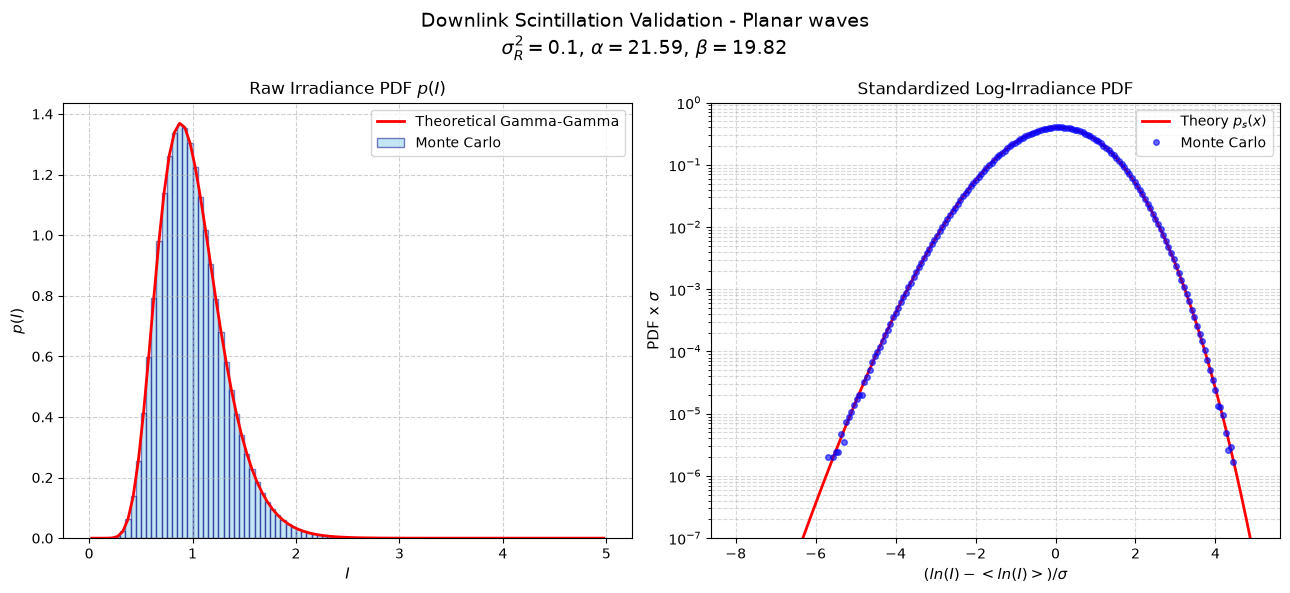

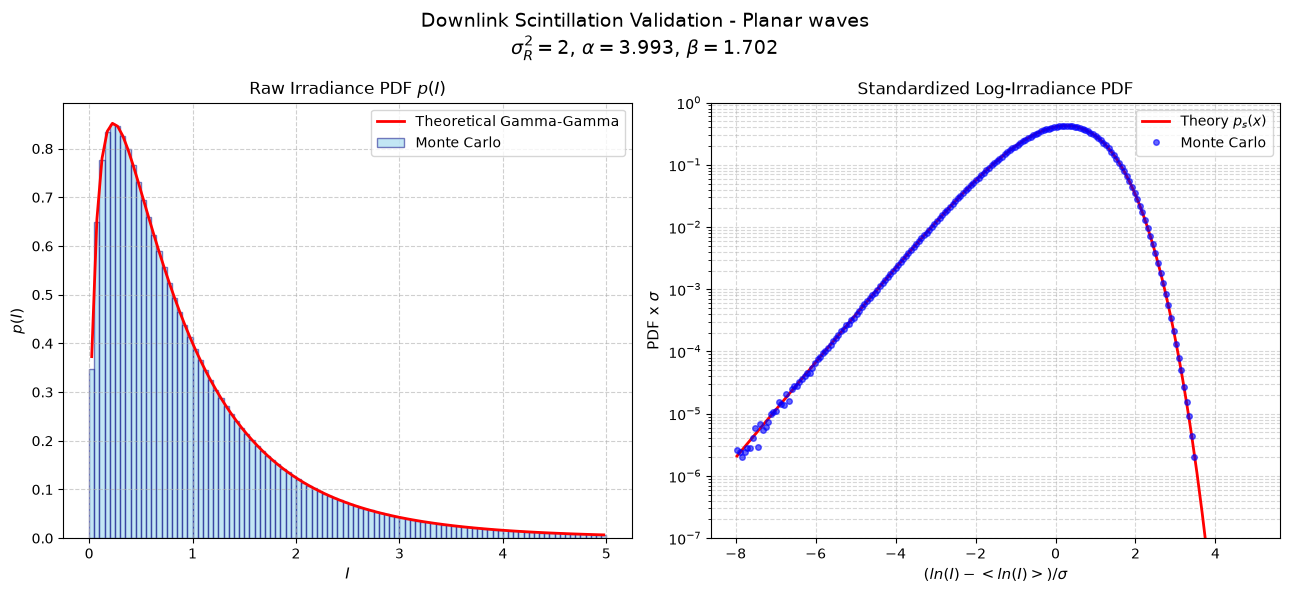

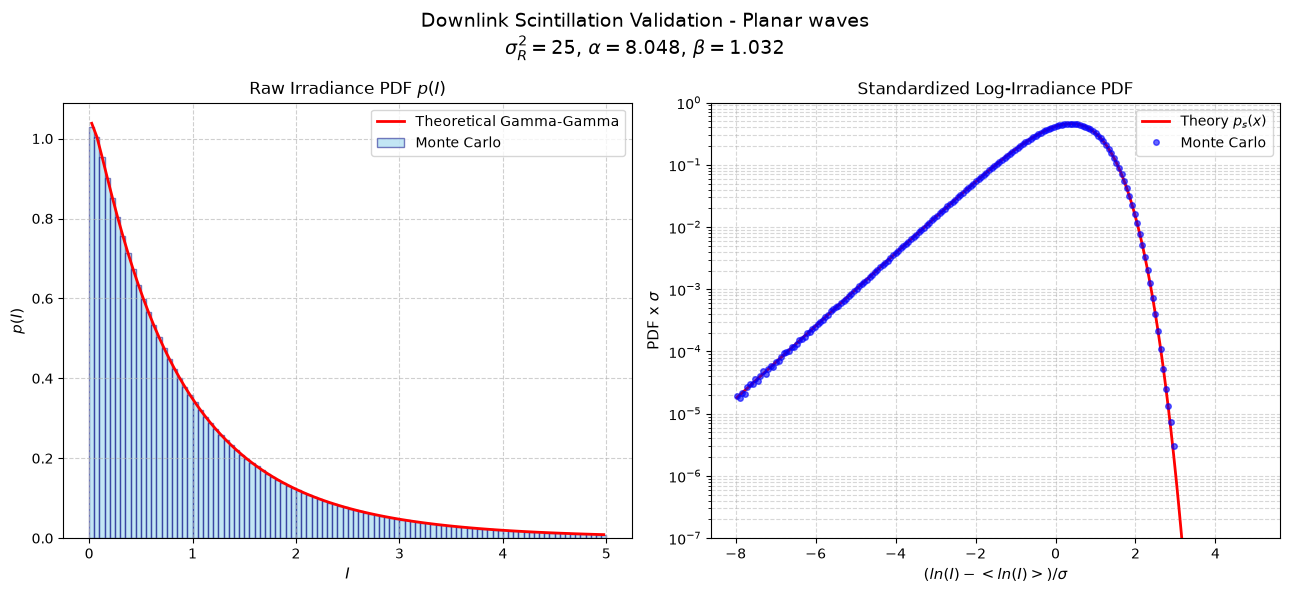

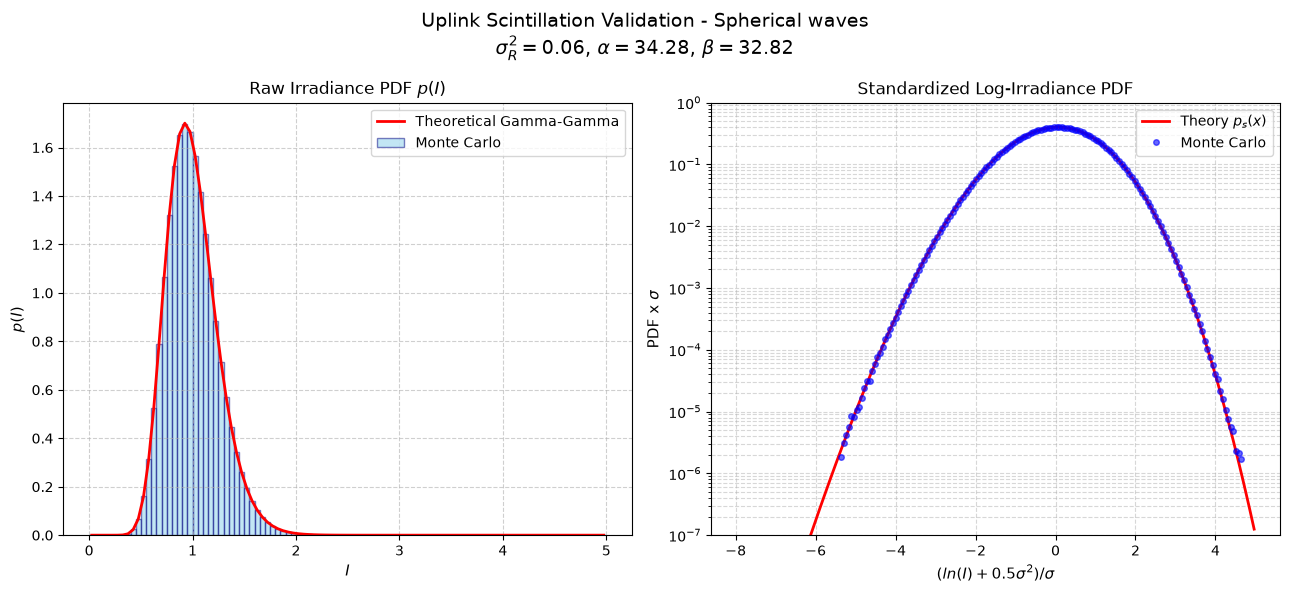

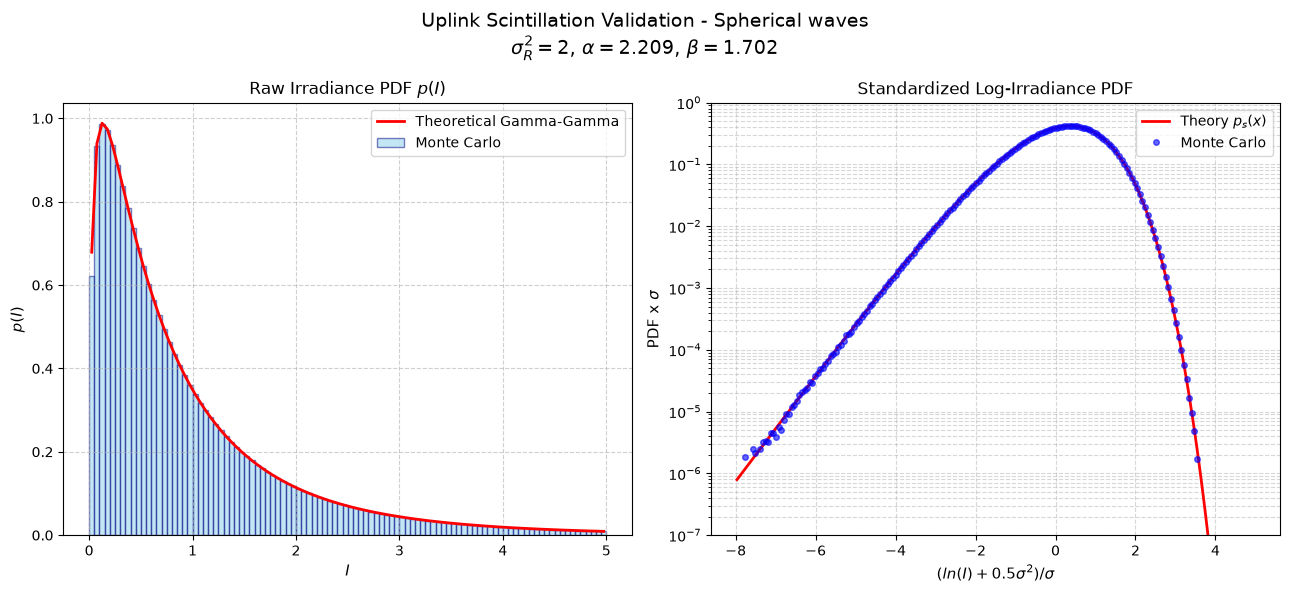

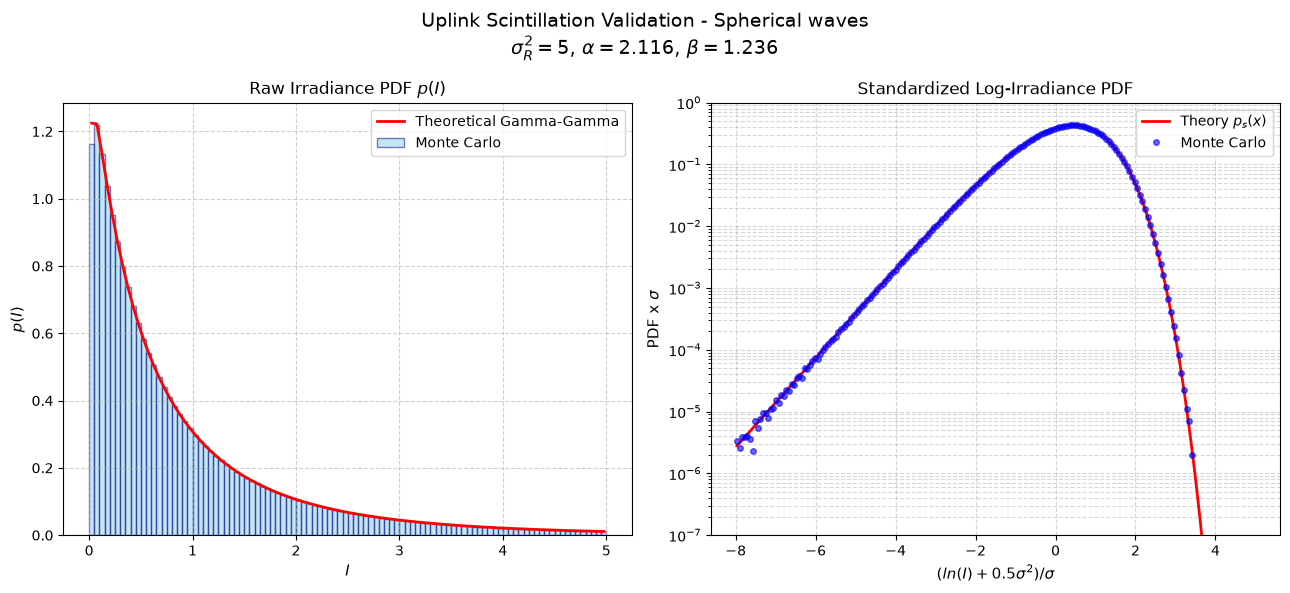

In [4]:
# We want to replicate the figures in sections 9.10.1 and 9.10.2 of L. C. Andrews and R. L. Phillips, "Laser Beam Propagation through Random Media".

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

INPUT_FILE = "qdl_fso_scintillation_validation.csv"
df = pd.read_csv(INPUT_FILE)

scenarios = df["scenario"].unique()
rytov_values = sorted(df["rytov"].unique())

N_SAMPLES = 100000000
X_BIN_WIDTH = (5.0 - (-8.0)) / 200
MIN_COUNT = 10                      # bins with fewer counts are too noisy
MC_PDF_THRESHOLD = MIN_COUNT / (N_SAMPLES * X_BIN_WIDTH)

# ------------------------------------------------------------
# Plot each scenario / Rytov variance combination
# ------------------------------------------------------------

for scenario in scenarios:
    for rytov in rytov_values:

        # Select one validation case
        case_df = df[
            (df["scenario"] == scenario)
            & (df["rytov"] == rytov)
        ]

        if case_df.empty:
            continue

        # Separate raw irradiance and standardized log-irradiance
        df_raw = case_df[
            case_df["type"] == "raw_irradiance"
        ].sort_values("x_val")

        df_log = case_df[
            case_df["type"] == "standardized_log"
        ].sort_values("x_val")

        df_mc_log = df_log[df_log["mc_pdf"] >= MC_PDF_THRESHOLD]

        # Alpha and beta are constant for this validation case
        alpha = case_df["alpha"].iloc[0]
        beta = case_df["beta"].iloc[0]

        # ----------------------------------------------------
        # Create figure
        # ----------------------------------------------------

        fig, axes = plt.subplots(
            1,
            2,
            figsize=(13, 6)
        )

        if scenario == "Downlink":
            wave_type = "Planar"
            x_label = r"$(ln(I) - <ln(I)>)/\sigma$"
        elif scenario == "Uplink":
            wave_type = "Spherical"
            x_label = r"$(ln(I) + 0.5 \sigma^2)/\sigma$"
        else:
            wave_type = None
            x_label = None

        fig.suptitle(
            f"{scenario.capitalize()} Scintillation Validation - {wave_type} waves\n"
            rf"$\sigma_R^2 = {rytov:.3g}$, "
            rf"$\alpha = {alpha:.4g}$, "
            rf"$\beta = {beta:.4g}$",
            fontsize=14
        )

        # ====================================================
        # Raw Irradiance PDF
        # ====================================================

        if len(df_raw) > 1:
            bin_width = (
                df_raw["x_val"]
                .sort_values()
                .diff()
                .dropna()
                .mean()
            )
        else:
            bin_width = 0.1

        axes[0].bar(
            df_raw["x_val"],
            df_raw["mc_pdf"],
            width=bin_width,
            alpha=0.5,
            color="skyblue",
            edgecolor="navy",
            label="Monte Carlo"
        )

        axes[0].plot(
            df_raw["x_val"],
            df_raw["theory_pdf"],
            "r-",
            lw=2,
            label="Theoretical Gamma-Gamma"
        )

        axes[0].set_title(
            r"Raw Irradiance PDF $p(I)$",
            fontsize=12
        )

        axes[0].set_xlabel(
            r"$I$",
            fontsize=11
        )

        axes[0].set_ylabel(
            r"$p(I)$",
            fontsize=11
        )

        axes[0].grid(
            True,
            linestyle="--",
            alpha=0.6
        )

        axes[0].legend(fontsize=10)

        # ====================================================
        # Standardized Log-Irradiance PDF
        # ====================================================

        axes[1].plot(
            df_log["x_val"],
            df_log["theory_pdf"],
            "r-",
            lw=2,
            label=r"Theory $p_s(x)$"
        )

        axes[1].plot(
            df_mc_log["x_val"],
            df_mc_log["mc_pdf"],
            "bo",
            markersize=4,
            alpha=0.6,
            label="Monte Carlo"
        )

        axes[1].set_yscale("log")
        axes[1].set_ylim(1e-7, 1.0)

        axes[1].set_title(
            r"Standardized Log-Irradiance PDF",
            fontsize=12
        )

        axes[1].set_xlabel(
            x_label,
            fontsize=11
        )

        axes[1].set_ylabel(
            r"PDF x $\sigma$",
            fontsize=11
        )

        axes[1].grid(
            True,
            which="both",
            linestyle="--",
            alpha=0.5
        )

        axes[1].legend(fontsize=10)

        plt.tight_layout()

        plt.show()

        plt.close(fig)

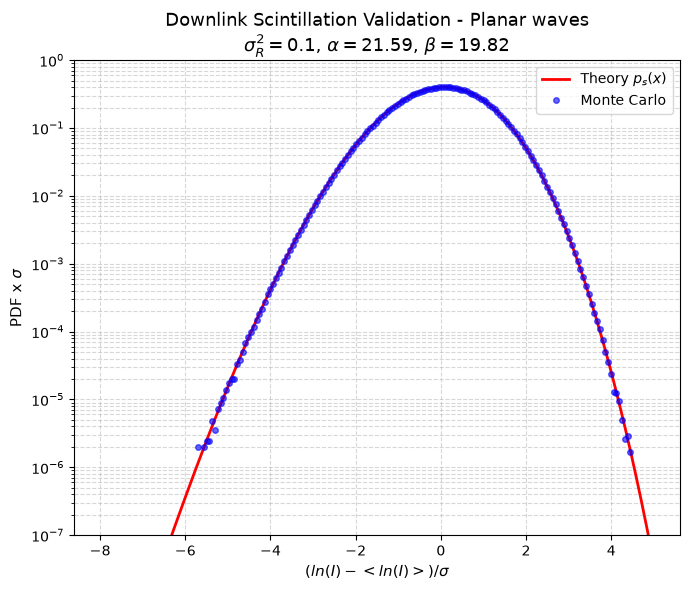

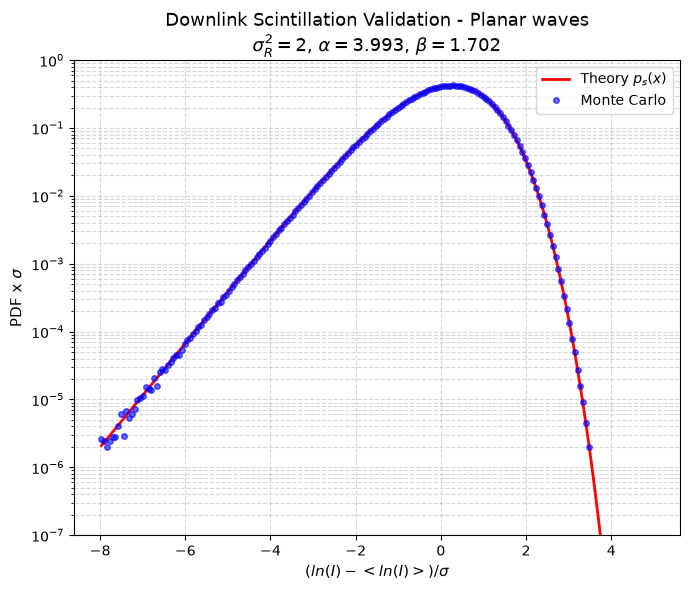

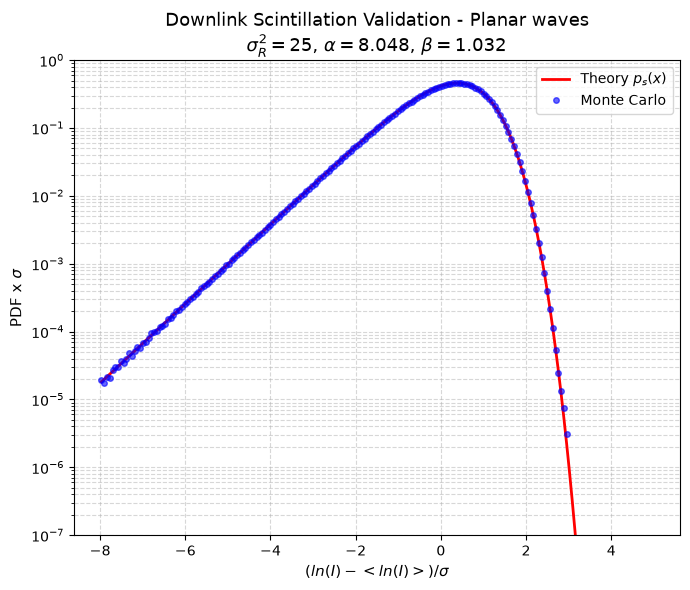

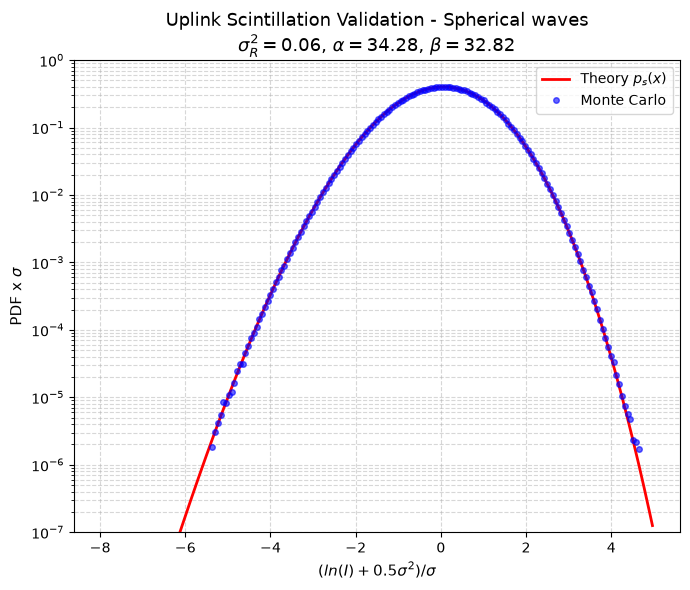

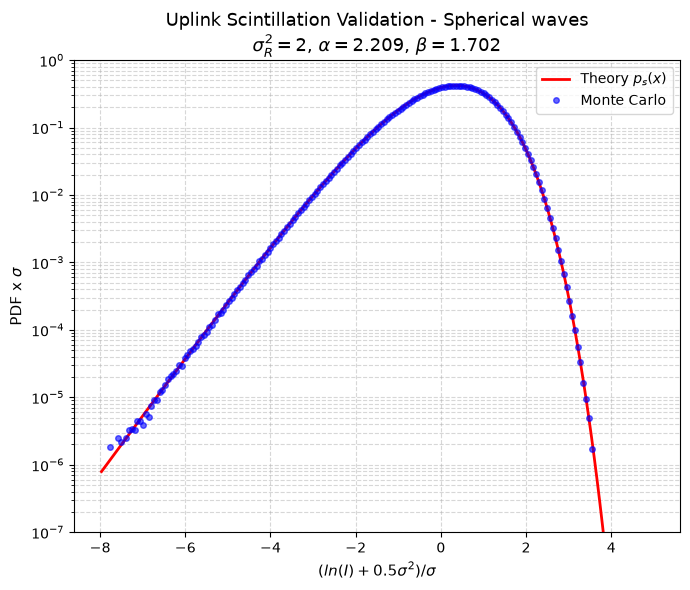

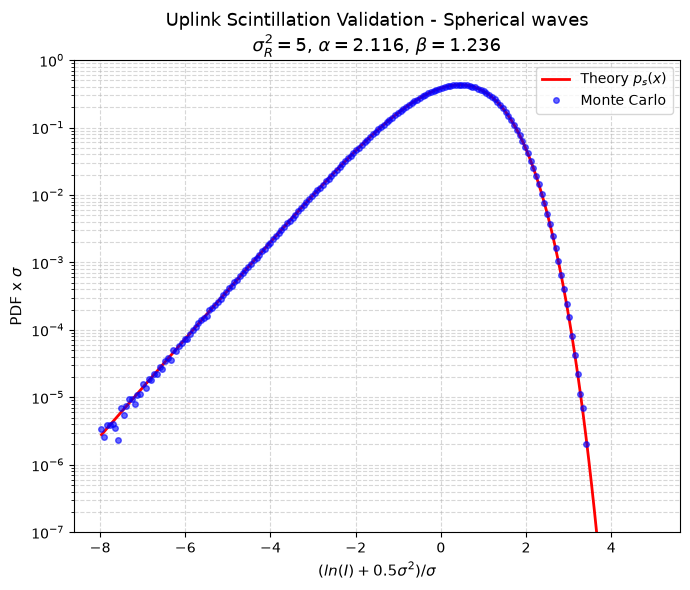

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Load data
# ------------------------------------------------------------

INPUT_FILE = "qdl_fso_scintillation_validation.csv"
OUTPUT_DIR = "./figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(INPUT_FILE)

scenarios = df["scenario"].unique()
rytov_values = sorted(df["rytov"].unique())

N_SAMPLES = 100000000
X_BIN_WIDTH = (5.0 - (-8.0)) / 200
MIN_COUNT = 10                      # bins with fewer counts are too noisy
MC_PDF_THRESHOLD = MIN_COUNT / (N_SAMPLES * X_BIN_WIDTH)

# ------------------------------------------------------------
# Plot each scenario / Rytov variance combination
# ------------------------------------------------------------

for scenario in scenarios:
    for rytov in rytov_values:

        # Select one validation case
        case_df = df[
            (df["scenario"] == scenario)
            & (df["rytov"] == rytov)
        ]

        if case_df.empty:
            continue

        # Only the standardized log-irradiance data is needed
        df_log = case_df[
            case_df["type"] == "standardized_log"
        ].sort_values("x_val")

        df_mc_log = df_log[df_log["mc_pdf"] >= MC_PDF_THRESHOLD]

        if df_mc_log.empty:
            continue

        # Alpha and beta are constant for this validation case
        alpha = case_df["alpha"].iloc[0]
        beta = case_df["beta"].iloc[0]

        if scenario == "Downlink":
            wave_type = "Planar"
            x_label = r"$(ln(I) - <ln(I)>)/\sigma$"
        elif scenario == "Uplink":
            wave_type = "Spherical"
            x_label = r"$(ln(I) + 0.5 \sigma^2)/\sigma$"
        else:
            wave_type = None
            x_label = None

        # ----------------------------------------------------
        # Create figure (single panel)
        # ----------------------------------------------------

        fig, ax = plt.subplots(figsize=(7, 6))

        ax.set_title(
            f"{scenario.capitalize()} Scintillation Validation - {wave_type} waves\n"
            rf"$\sigma_R^2 = {rytov:.3g}$, "
            rf"$\alpha = {alpha:.4g}$, "
            rf"$\beta = {beta:.4g}$",
            fontsize=13
        )

        ax.plot(
            df_log["x_val"],
            df_log["theory_pdf"],
            "r-",
            lw=2,
            label=r"Theory $p_s(x)$"
        )

        ax.plot(
            df_mc_log["x_val"],
            df_mc_log["mc_pdf"],
            "bo",
            markersize=4,
            alpha=0.6,
            label="Monte Carlo"
        )

        ax.set_yscale("log")
        ax.set_ylim(1e-7, 1.0)

        ax.set_xlabel(x_label, fontsize=11)
        ax.set_ylabel(r"PDF x $\sigma$", fontsize=11)

        ax.grid(True, which="both", linestyle="--", alpha=0.5)
        ax.legend(fontsize=10)

        plt.tight_layout()

        # plt.savefig(f"{OUTPUT_DIR}/qdl_fso_scintillation_{rytov}_{scenario.lower()}.pdf")
        plt.savefig(f"{OUTPUT_DIR}/qdl_fso_scintillation_{rytov}_{scenario.lower()}.png")

        plt.show()
        plt.close(fig)